# Historical MODIS NDVI baseline (2002–2019) and 2020 anomalies

**Original research:** Aster Volta, NASA/JPL Mongolia dzud study (2022). **Reconstruction:** source-validated 2026.

A full, honest historical reference was rebuilt using the **54 original monthly Earth Engine exports for 2002–2019** (18 June + 18 July + 18 August). The 2020 targets were NOT used to calculate their baseline. Product: `MODIS/MOD09GA_006_NDVI`, distinct from Giovanni MOD13C2 used in notebook 01.

Baseline rasters and 2020 target rasters are packaged here, so this notebook works offline; original 54 historical source rasters are catalogued in the SHA-256 manifest and can optionally regenerate the baseline via `python -m src.climatology --original-folder <folder>`. No artificial observations.

In [1]:
from pathlib import Path
import sys
PROJECT=Path.cwd()
if not (PROJECT/'src').exists(): PROJECT=PROJECT.parent
assert (PROJECT/'src').exists(), 'Launch Jupyter from repo root or notebooks/'
sys.path.insert(0,str(PROJECT))
from IPython.display import display,Image
import pandas as pd


## Check the 18-year monthly reference and calculate actual NDVI anomalies

The original Earth Engine exports use an identical fixed zero-filled mask. These locations are excluded from the climatology, rather than falsely treated as zero vegetation. The same grid and CRS are checked for all years.

In [2]:
from src.climatology import compute_gee_2020_anomalies,CLIM,RESULTS
monthly, jja = compute_gee_2020_anomalies()
print('Original historical satellite rasters used:',len(pd.read_csv(CLIM/'historical_54_file_SHA256_source_manifest.csv')))
print('Monthly province estimates:',len(monthly),'province summer estimates:',len(jja))
display(pd.read_csv(CLIM/'baseline_generation_QA.csv')[['month','historical_years','fully_valid_reference_cells','zero_mask_fraction']])

Original historical satellite rasters used: 54
Monthly province estimates: 66 province summer estimates: 22


,month,historical_years,fully_valid_reference_cells,zero_mask_fraction
0,June,18,2294963,0.45596
1,July,18,2294963,0.45596
2,August,18,2294963,0.45596


## Mapped 2020 departures from the 2002–2019 climatology

These are *genuine historical-reference anomalies*, not differences from 2019 alone. Blue means more NDVI than the month-specific historical mean; red means less. This is descriptive vegetation evidence, **not proof that a particular winter dzud was caused by low NDVI**.

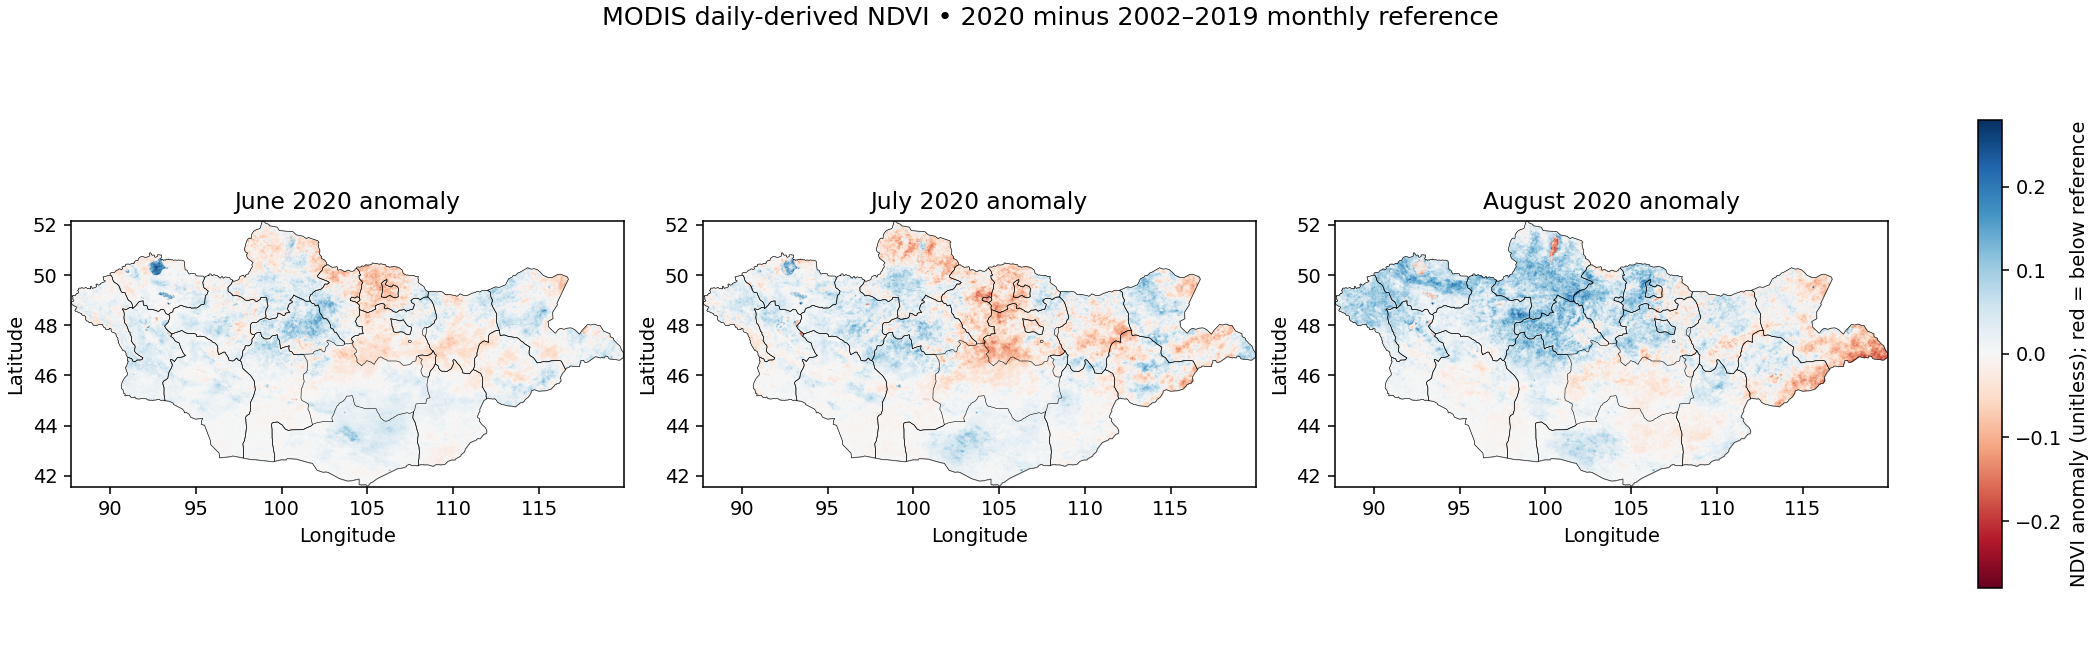

,province_key,ndvi_true_anomaly_jja_2020
4,darkhanuul,-0.0299
13,orkhon,-0.0217
16,tuv,-0.0097
14,selenge,-0.0073
20,uvurkhangai,-0.0062
15,sukhbaatar,-0.0056
10,khentii,-0.0040
5,dornod,-0.0021
7,dundgovi,-0.0006
9,govisumber,0.0018


Provinces with negative 2020 June–August mean anomaly: 9 of 22


In [3]:
display(Image(filename=str(RESULTS/'07_ndvi_2020_true_historical_anomaly.png'),width=1100))
display(jja.sort_values('ndvi_true_anomaly_jja_2020').head(10).round(4))
print('Provinces with negative 2020 June–August mean anomaly:',int((jja.ndvi_true_anomaly_jja_2020<0).sum()),'of',len(jja))

## Method provenance and limitations

The 54 TIFFs were produced in the original 2022 notebook using a monthly mean of GEE daily MODIS NDVI at ~1-km export scale, **not** the separately processed NASA Giovanni MOD13C2 monthly series. The derived 2002–2019 baseline is published here with its exact source hashes. No original daily cloud/QA bits were available with the historical TIFF exports; sensitivity to those flags cannot be quantified from this archive. Every map is aligned on a common grid, and 2020 is not part of the reference.